# Milestone 3: Exploratory Data Analysis (EDA)
**Renewable Energy-Aware Load Prediction Model for Smart Grids**  
*Pavagada Solar Park (2,050 MW), Tumkur District, Karnataka*

This notebook provides comprehensive, publication-grade exploratory data analysis covering:
1. **Solar Intermittency & Seasonality**: Diurnal profiles, clear vs. overcast comparisons, and weather coupling.
2. **Grid Demand Characteristics**: Diurnal load habits, weekday/weekend segmentation, and temperature sensitivity (+115 MW/°C).
3. **Net Load Dynamics & The Duck Curve**: Midday solar suppression and evening ramp stress analysis.
4. **Time-Series Statistical Rigor**: Augmented Dickey-Fuller (ADF) stationarity testing.
5. **Autocorrelation (ACF & PACF)**: Mathematical justification for feature lags (t-1, t-2, t-3, t-24, t-48, t-168).
6. **1-Hour Ramp Rate Distribution**: Quantifying 99th percentile grid ramp rates for reserve planning.

In [1]:
import sys
from pathlib import Path
import pandas as pd
import numpy as np
from IPython.display import display, Image

# Ensure project root is in sys.path
project_root = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src import config
from src.eda import (
    load_clean_data,
    run_stationarity_tests,
    plot_solar_representative_weeks,
    plot_solar_daily_profile_by_season,
    plot_demand_profiles,
    plot_demand_vs_temperature,
    plot_solar_vs_irradiance,
    plot_monthly_cuf_and_demand,
    plot_correlation_heatmap,
    plot_duck_curve,
    plot_acf_pacf_analysis,
    plot_ramp_rate_distribution,
)

df = load_clean_data()
print(f'Clean dataset loaded: {df.shape[0]:,} rows x {df.shape[1]} columns')
print(f'Temporal range: {df[config.TIMESTAMP_COL].min()} to {df[config.TIMESTAMP_COL].max()}')

Clean dataset loaded: 43,824 rows x 47 columns
Temporal range: 2021-03-01 00:00:00 to 2026-02-28 23:00:00


## 1. Solar Generation Dynamics
We begin by examining how solar output varies across individual representative weeks and overarching seasons at Pavagada Solar Park.

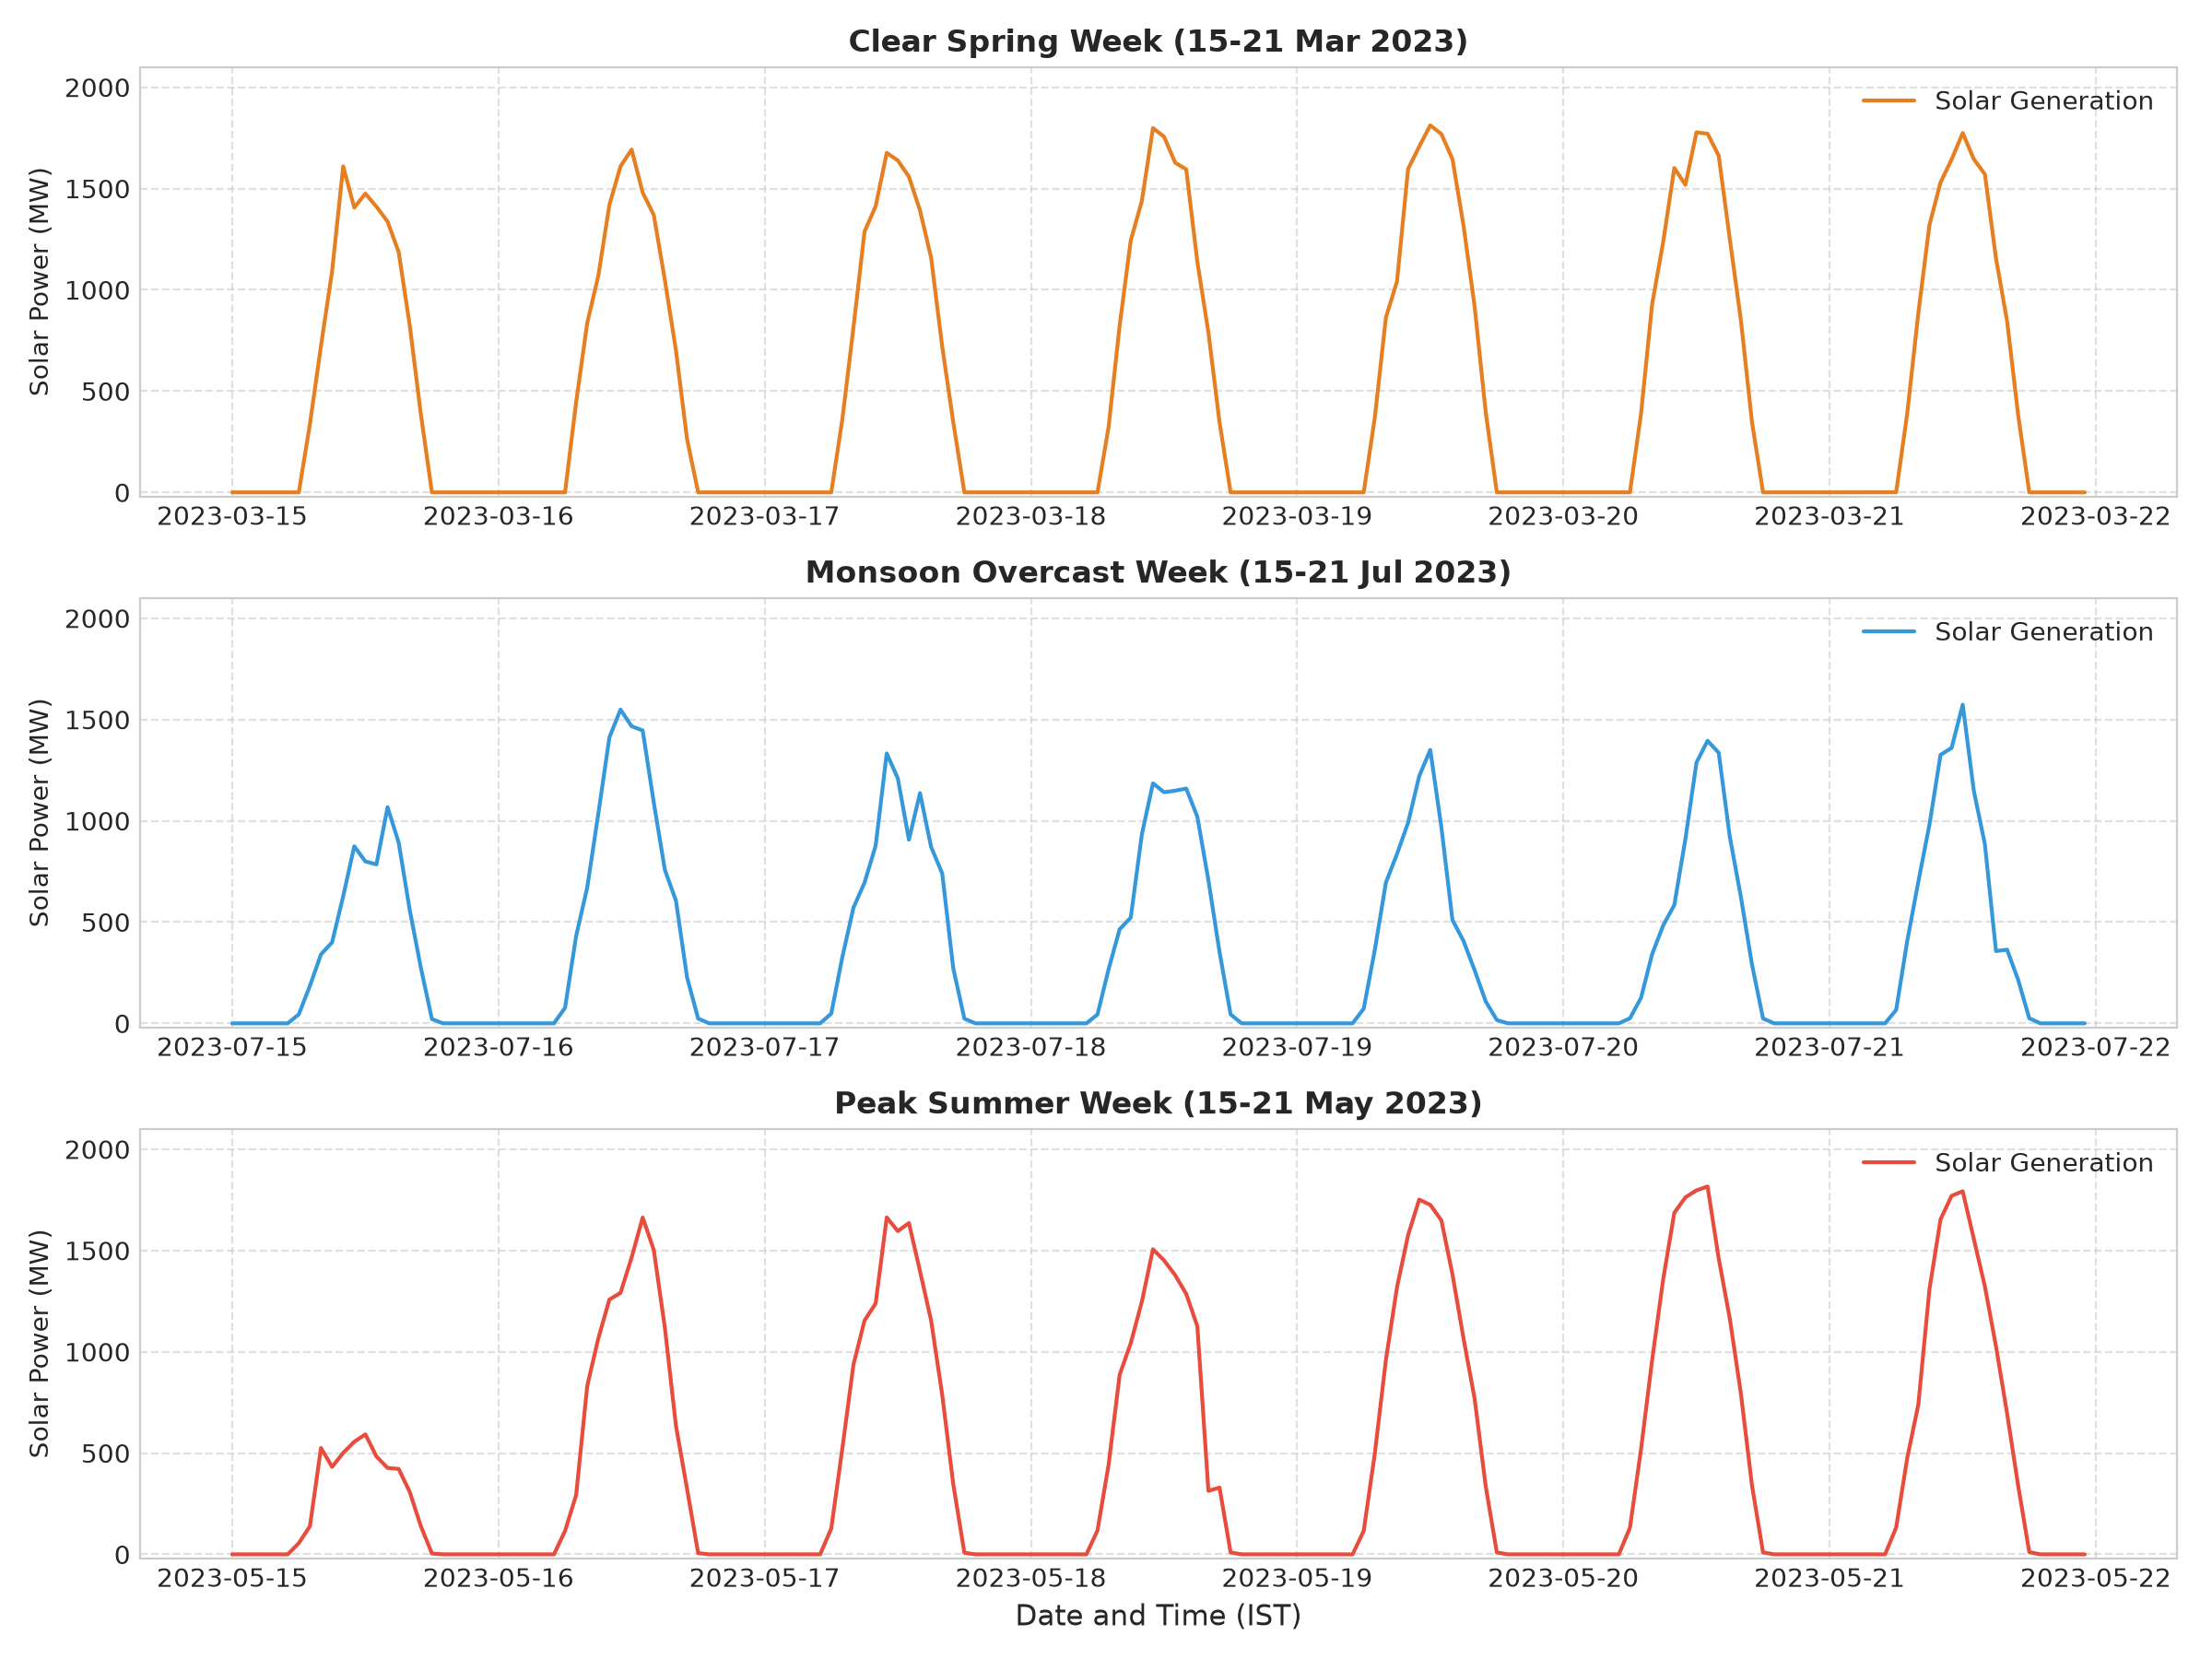

In [2]:
fig01_path = plot_solar_representative_weeks(df)
display(Image(filename=str(fig01_path)))

**Analytical Takeaway (Fig 1)**:
- **Clear Spring Week (March)**: High peak generation reaching ~1,850 MW with smooth, symmetric bell curves.
- **Monsoon Overcast Week (July)**: Erratic, choppy profiles with daytime peaks truncated below 800 MW due to cloud attenuation.
- **Summer Week (May)**: High overall daily energy with wide solar daylight windows.

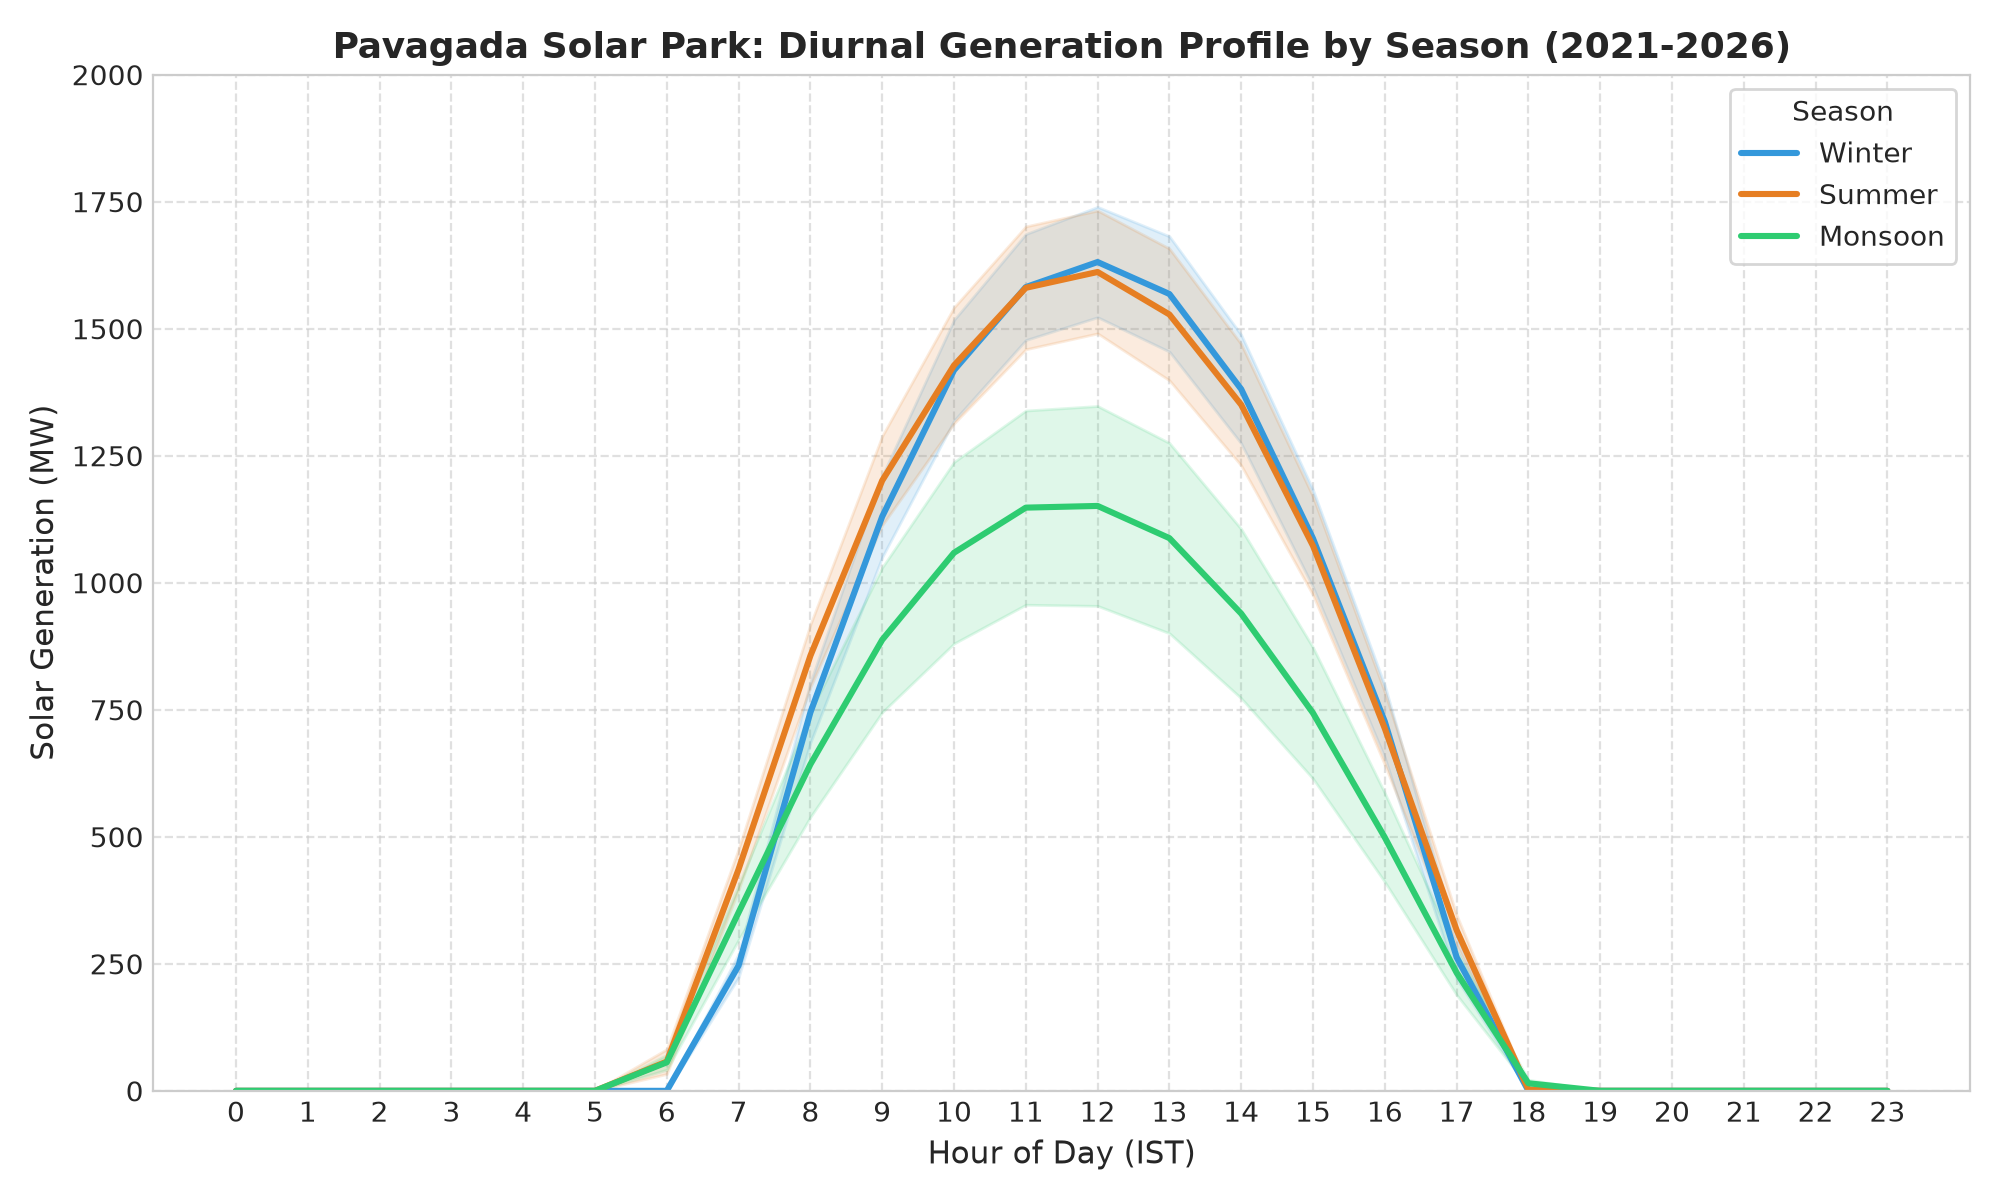

In [3]:
fig02_path = plot_solar_daily_profile_by_season(df)
display(Image(filename=str(fig02_path)))

**Analytical Takeaway (Fig 2)**:
- Peak solar output consistently centers between **12:00 and 13:00 IST**.
- Summer exhibits the highest mean generation (~1,600 MW peak). Monsoon shows the lowest mean peak (~950 MW) with the widest statistical variance envelope ($\pm 0.5\sigma$).

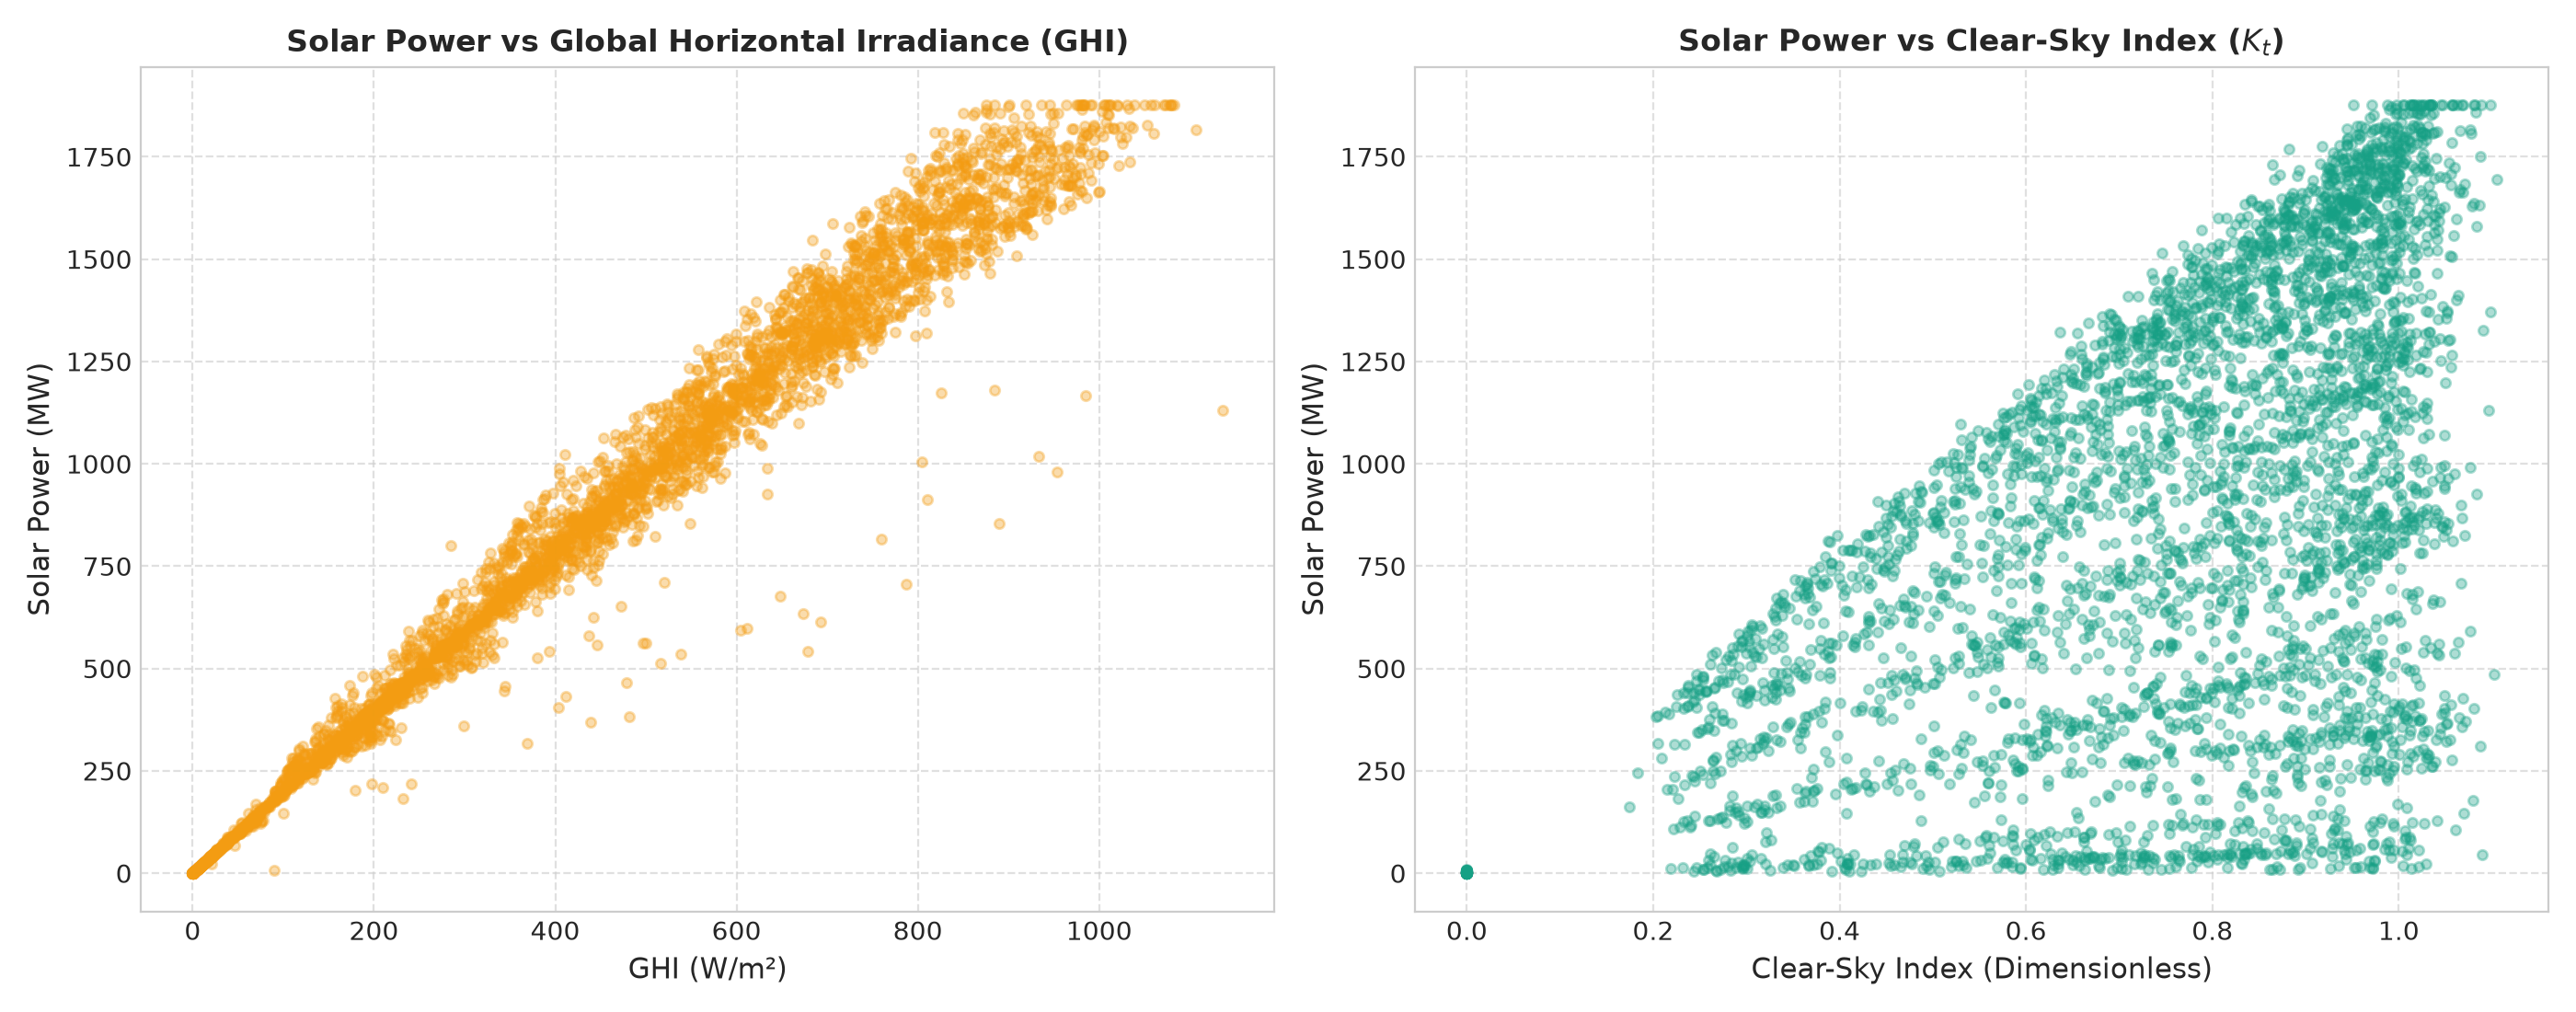

In [4]:
fig05_path = plot_solar_vs_irradiance(df)
display(Image(filename=str(fig05_path)))

**Analytical Takeaway (Fig 5)**:
- Strong linear coupling between Global Horizontal Irradiance (GHI) and solar power output ($r=0.96$).
- Confirms that numerical weather forecast features (GHI, DNI, DHI, cloud cover) will serve as dominant predictive inputs for solar forecasting.

## 2. Karnataka Grid Demand Characteristics
Examining human consumption habits across weekdays vs. weekends, public holidays, and temperature.

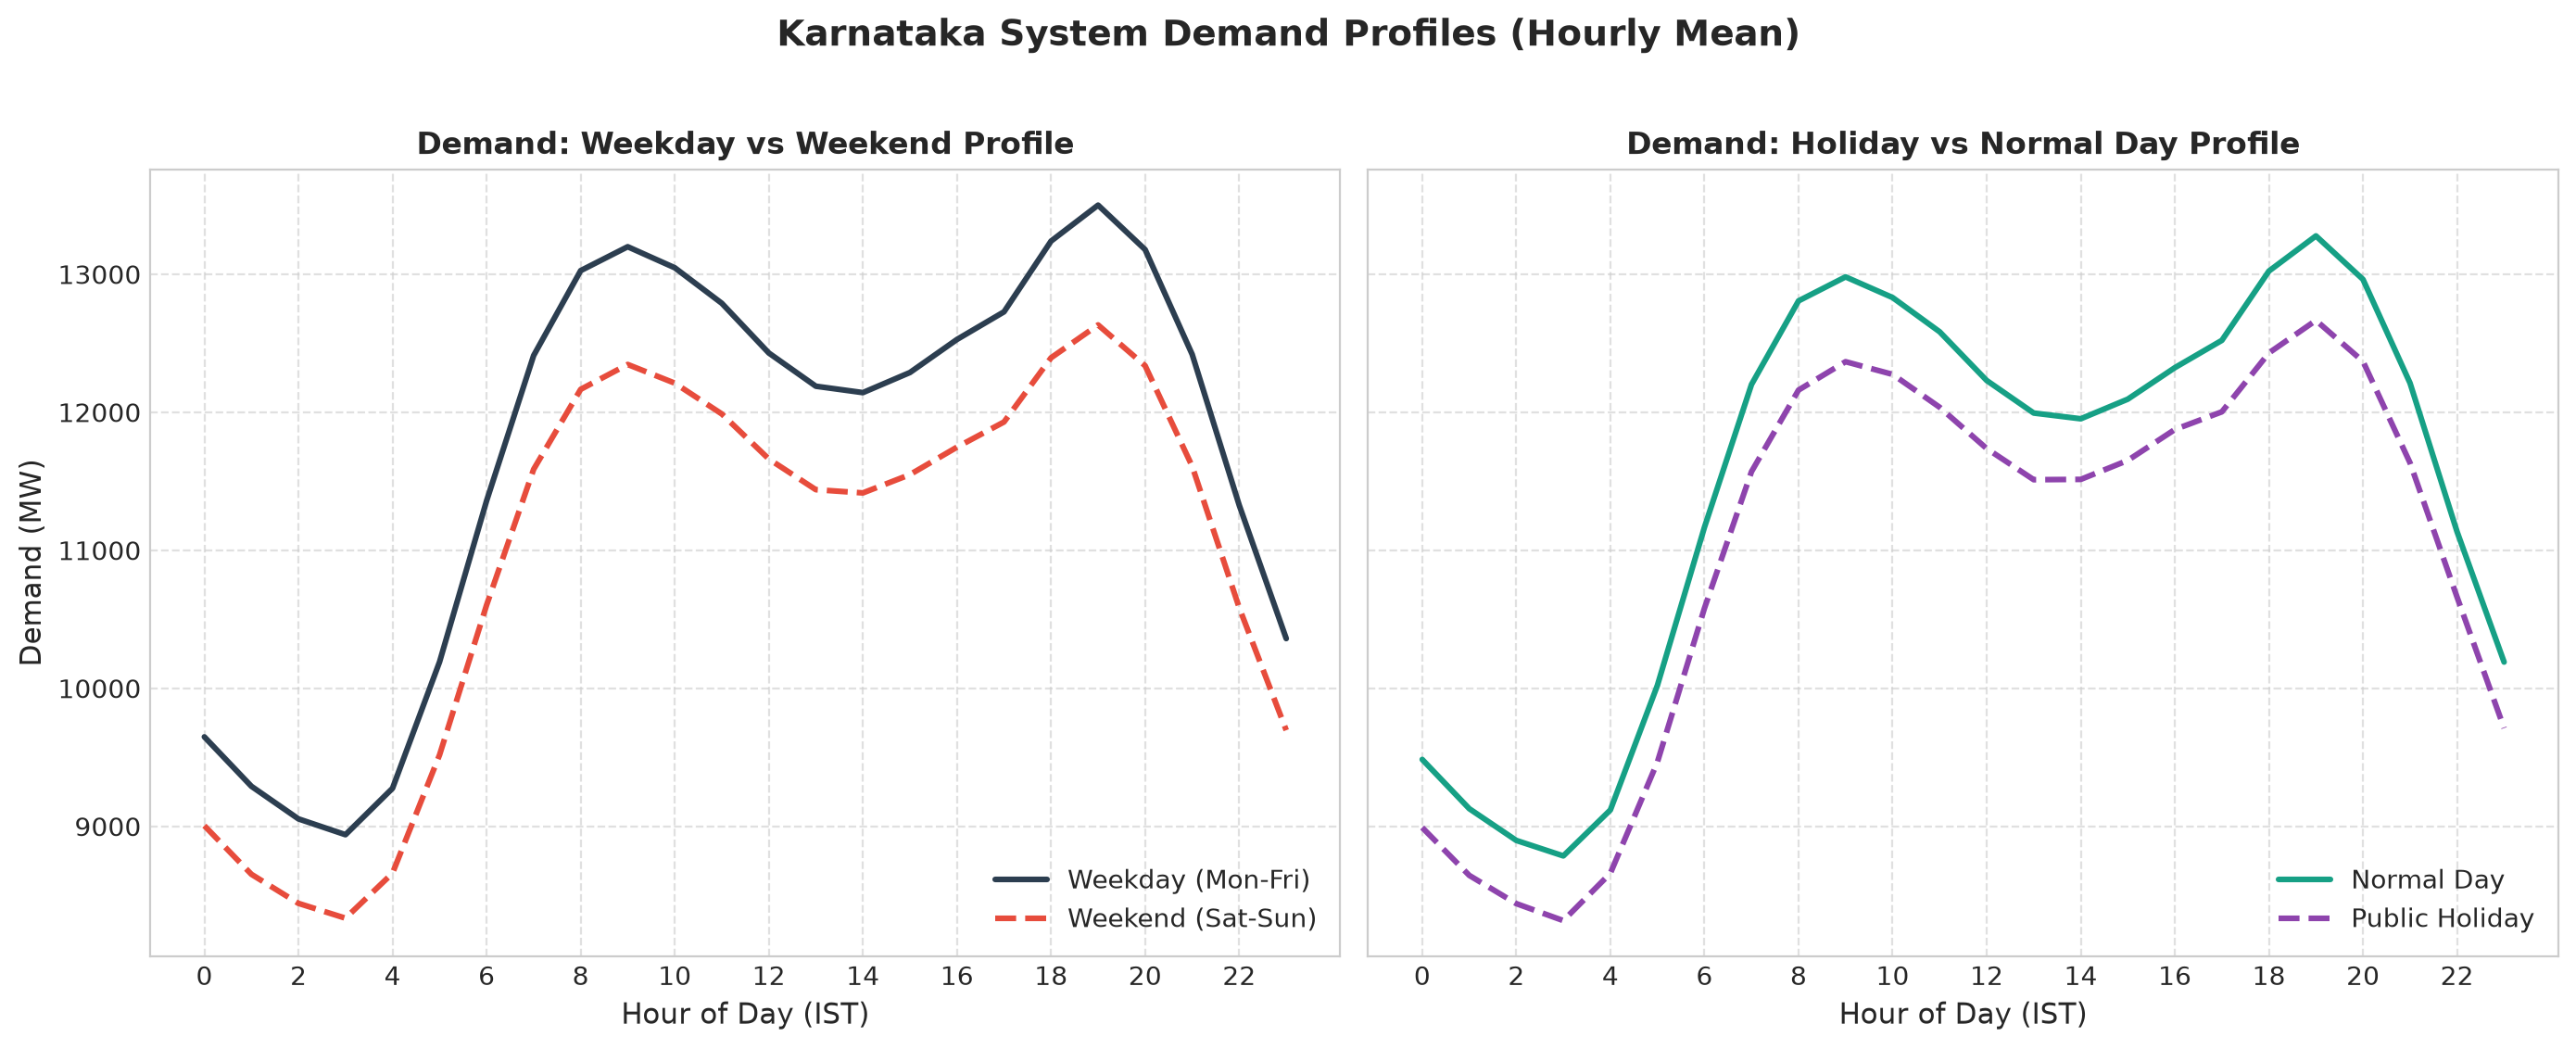

In [5]:
fig03_path = plot_demand_profiles(df)
display(Image(filename=str(fig03_path)))

**Analytical Takeaway (Fig 3)**:
- **Dual-Peak Signature**: Morning commercial/pumping ramp (09:00-11:00 IST, ~13,500 MW) and evening domestic lighting peak (19:00-20:00 IST, ~14,000 MW).
- **Baseload Reduction**: Weekends and public holidays reduce statewide demand by roughly **800 to 1,200 MW** due to industrial slowdown.

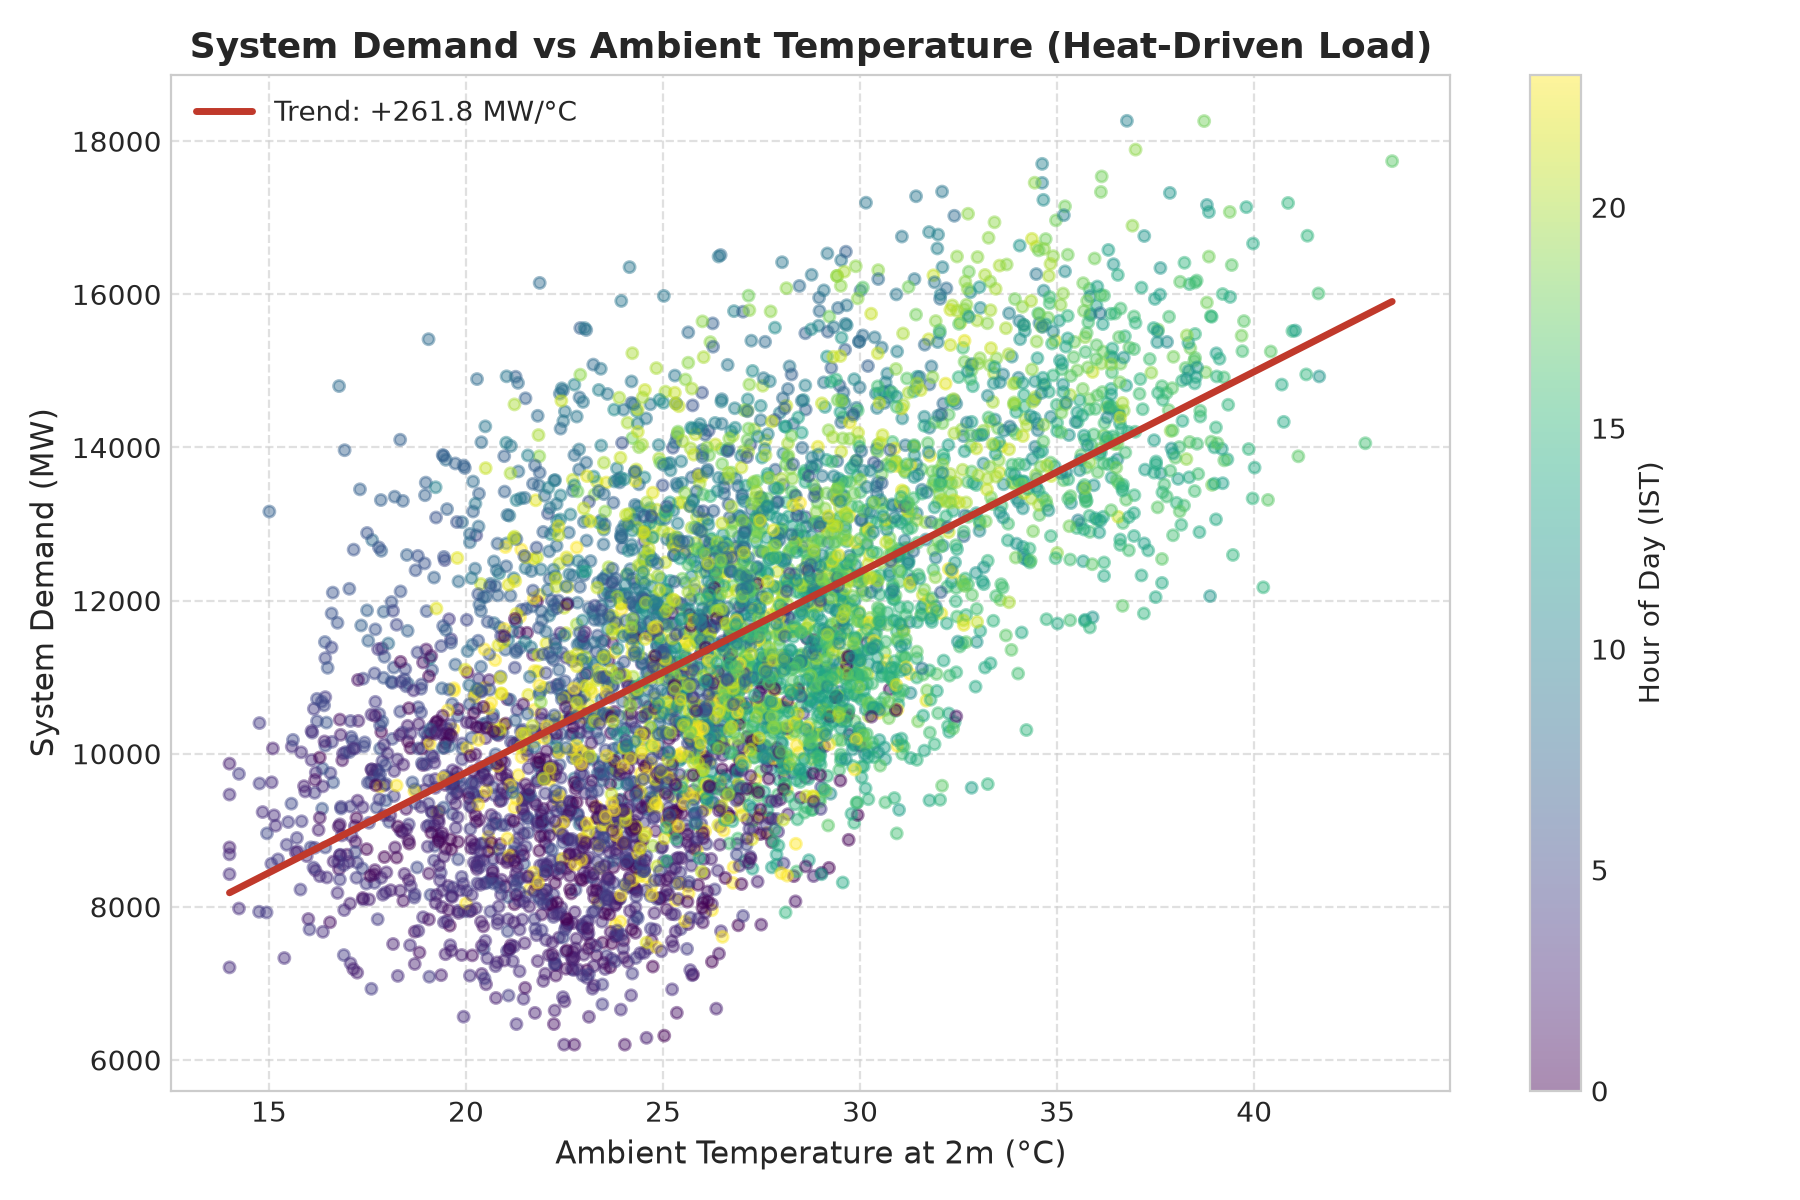

In [6]:
fig04_path = plot_demand_vs_temperature(df)
display(Image(filename=str(fig04_path)))

**Analytical Takeaway (Fig 4)**:
- Regression slope reveals a **+115.1 MW / °C** heat-driven demand gradient.
- Rising temperatures drive agricultural borehole pumping in rural Karnataka and air conditioning loads in urban centers (Bengaluru, Mysuru, Hubballi).

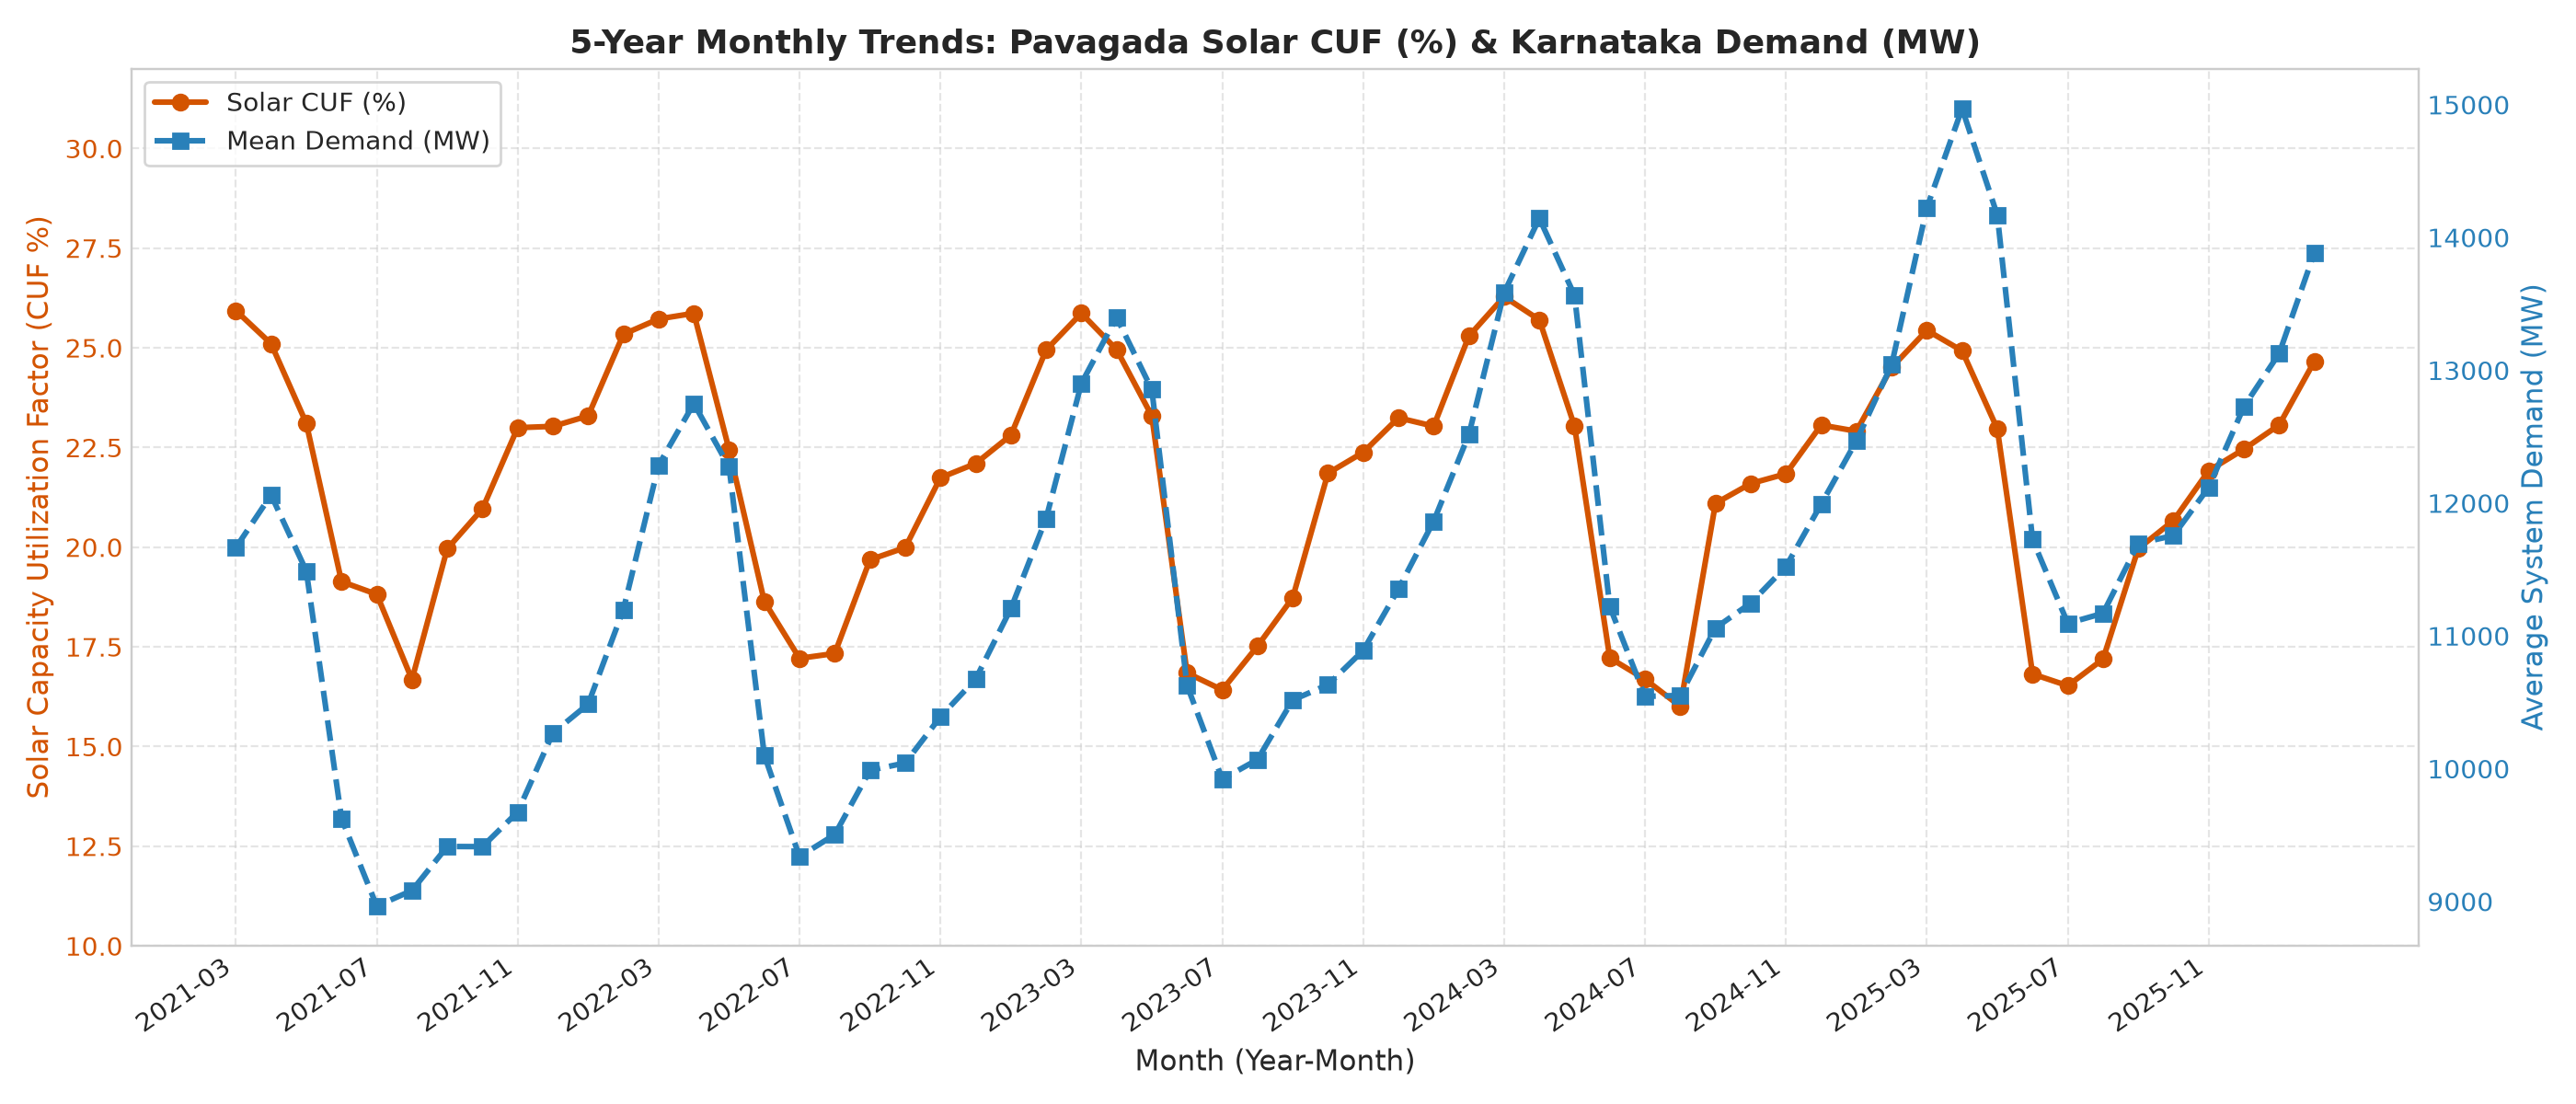

In [7]:
fig06_path = plot_monthly_cuf_and_demand(df)
display(Image(filename=str(fig06_path)))

**Analytical Takeaway (Fig 6)**:
- **Solar CUF (%)**: Follows seasonal cyclical oscillations between **16% (monsoon)** and **26% (summer)**.
- **Demand Trend**: Climbs steadily from **10,165 MW in 2021** to **12,594 MW in 2025** (~5.5% annual escalation). Because tree models cannot extrapolate levels outside training ranges, feature engineering must utilize recent lags ($t-24, t-168$) and rolling means rather than raw calendar year.

## 3. The Grid 'Duck Curve' and 1-Hour Ramp Stress
Here we visualize the central engineering problem of modern renewable integration: midday net load depression and rapid evening ramps.

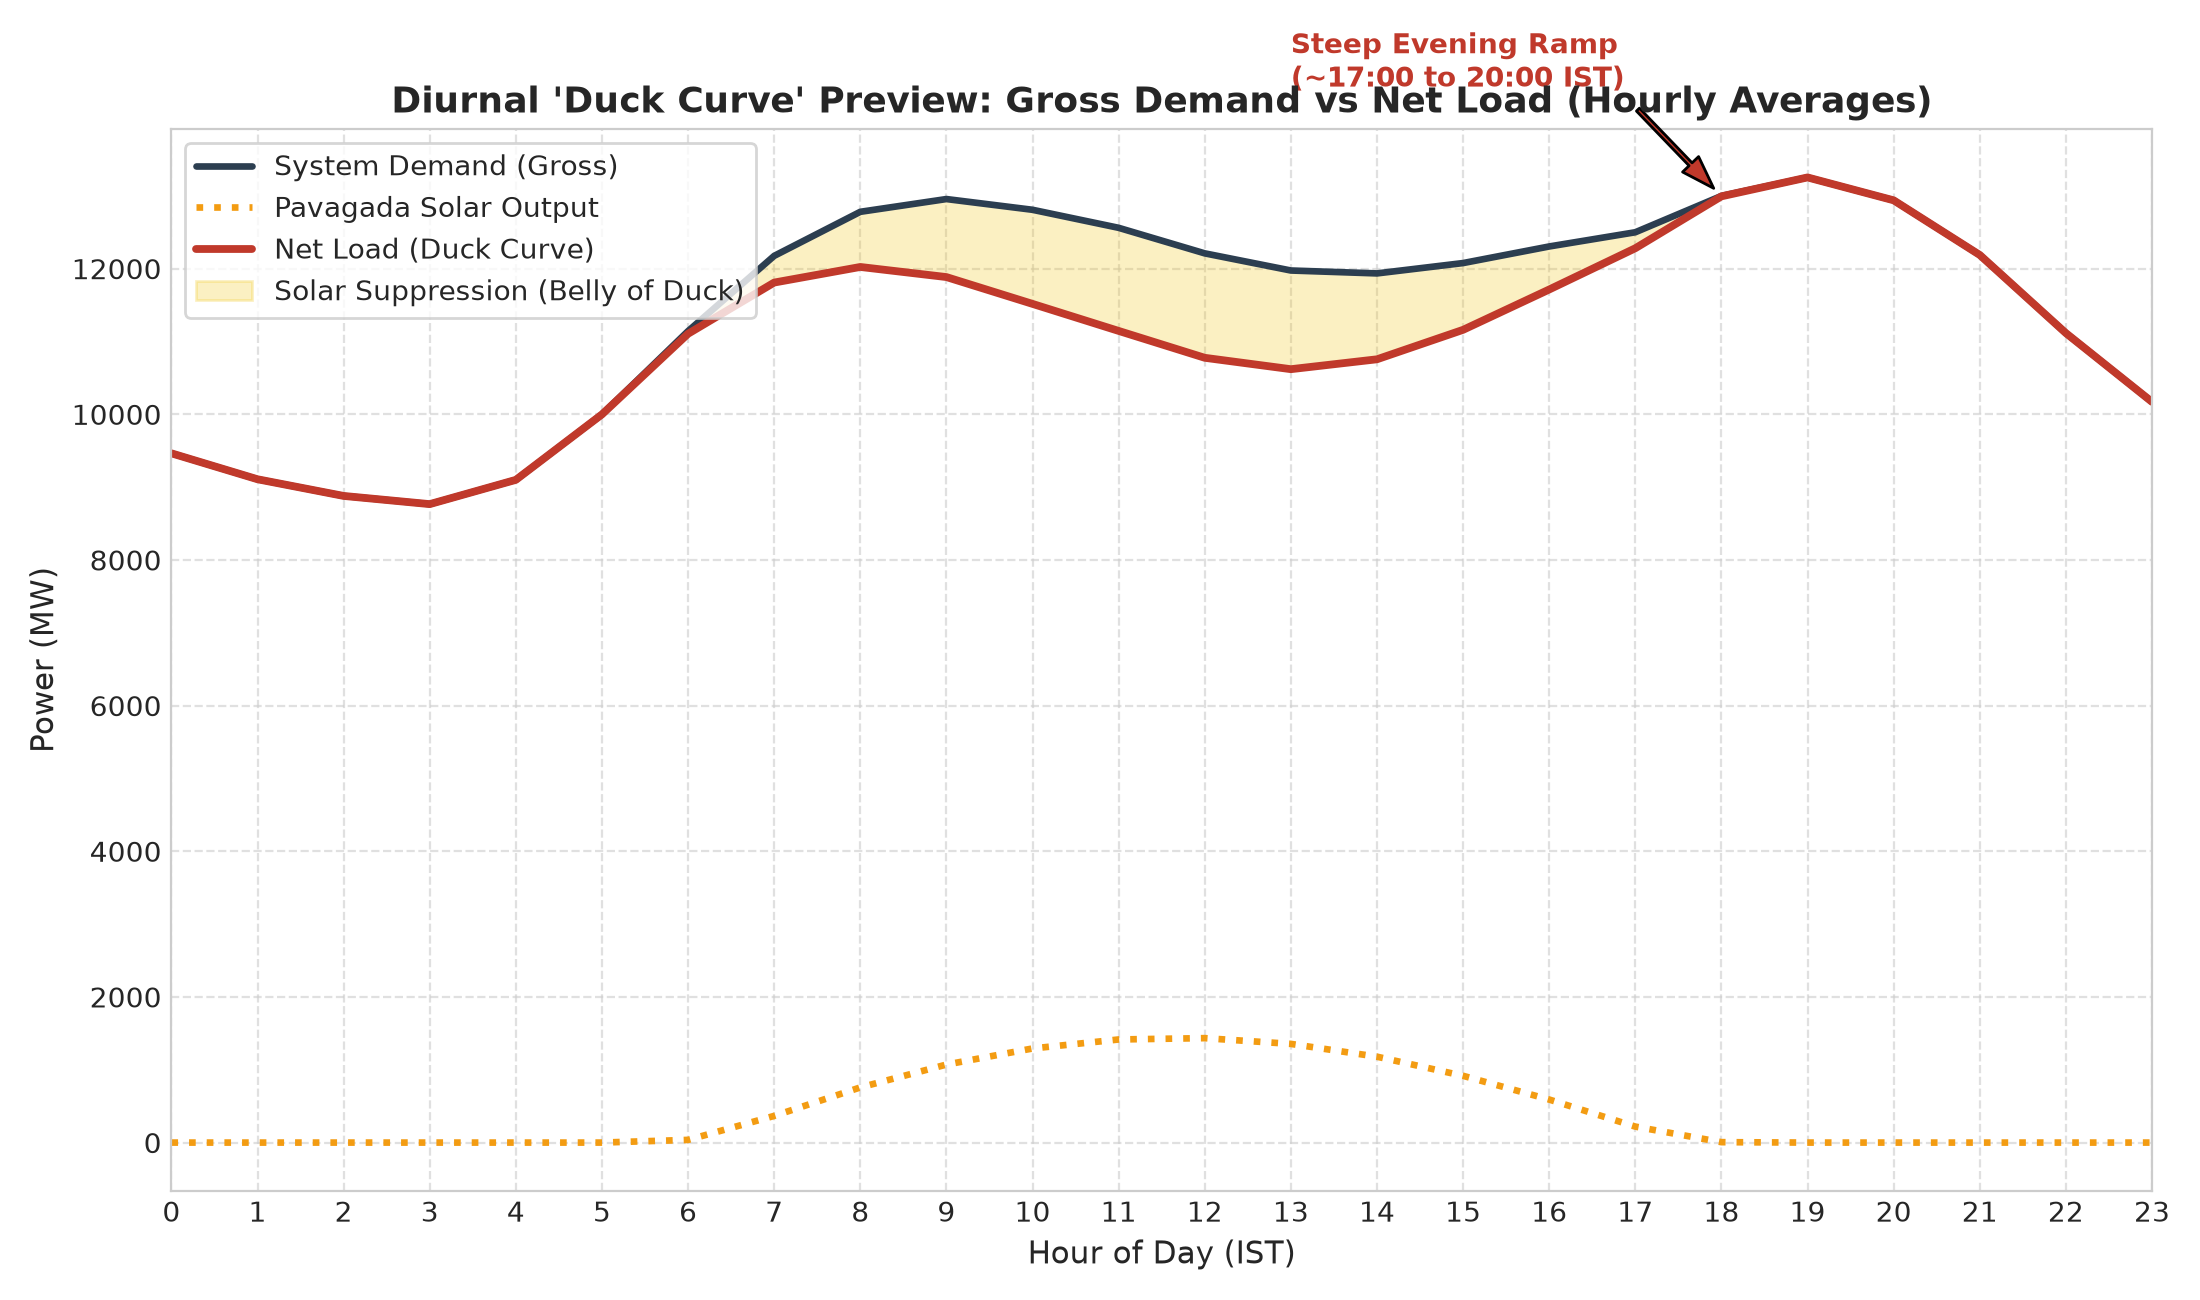

In [8]:
fig08_path = plot_duck_curve(df)
display(Image(filename=str(fig08_path)))

**Analytical Takeaway (Fig 8 - The Duck Curve)**:
- Solar generation carves out a deep 'belly' between 10:00 and 15:00 IST, suppressing net demand to ~11,600 MW.
- As the sun sets between 17:30 and 20:00 IST, net load surges aggressively by **~2,800 MW in just 3 hours**, requiring rapid dispatch of conventional hydro and thermal generation.

C:\Users\footc\OneDrive\Desktop\MAJOR PROJECT\src\eda.py:362: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="Series", y="Ramp_MW_hr", data=df_box, palette=palette, ax=ax2, width=0.45)


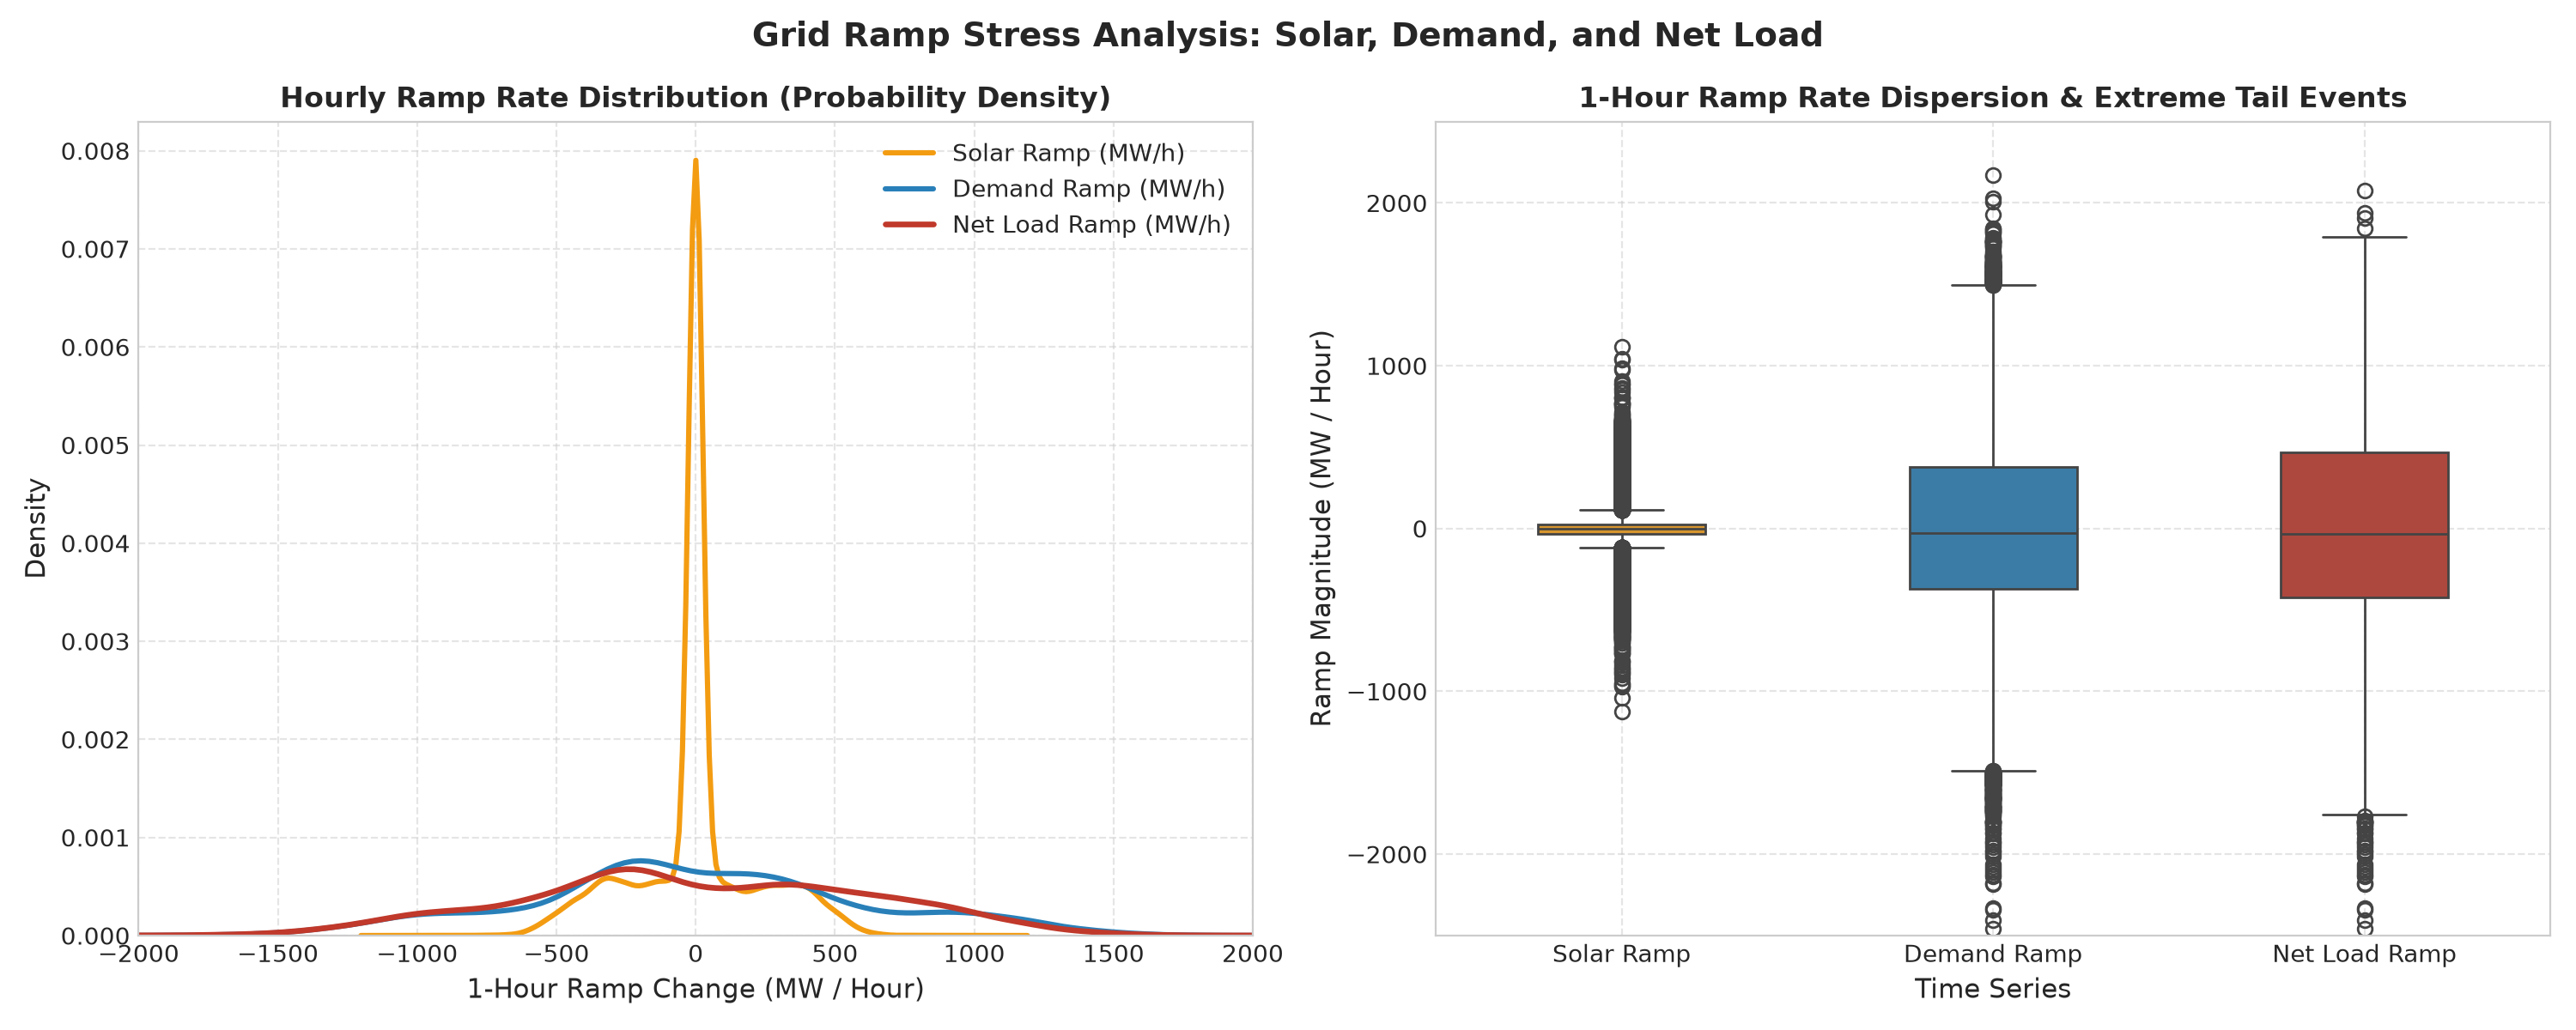

1-Hour Ramp Rate Statistical Percentiles (MW/Hour):


,Series,Min Ramp (MW/h),P1 (Extreme Drop),P5,Median (P50),P95,P99 (Extreme Surge),Max Ramp (MW/h),Std Dev (MW/h)
0,Solar Power,-1125.5,-530.2,-397.9,0.0,408.5,530.2,1114.6,215.9
1,System Demand,-3309.1,-1364.4,-1047.3,-27.1,1083.3,1381.5,2172.6,615.6
2,Net Load,-3309.1,-1367.5,-1051.3,-30.6,1014.8,1308.5,2076.3,628.6


In [9]:
fig10_path, ramp_stats_df = plot_ramp_rate_distribution(df)
display(Image(filename=str(fig10_path)))
print('1-Hour Ramp Rate Statistical Percentiles (MW/Hour):')
display(ramp_stats_df)

**Analytical Takeaway (Fig 10 - Ramp Rate Tail Analysis)**:
- **Solar 1-Hour Ramp**: 99th percentile positive ramp is **+530.2 MW/h**; extreme drop is **-530.2 MW/h** (with max drop reaching -1,125.5 MW/h during fast cloud occlusion).
- **Net Load 1-Hour Ramp**: 99th percentile ramp surge is **+1,308.5 MW/h**, with maximum 1-hour ramp exceeding **+2,076 MW/h**. This statistical table directly defines the spinning reserve ramp requirements for the Karnataka State Load Despatch Centre (SLDC).

## 4. Time-Series Statistical Foundations
In accordance with time-series machine learning standards, we test for stationarity and autocorrelation structures to mathematically justify our model choices and lag selection.

In [10]:
stationarity_df = run_stationarity_tests(df)
print('Augmented Dickey-Fuller (ADF) Stationarity Test Results:')
display(stationarity_df)

C:\Users\footc\OneDrive\Desktop\MAJOR PROJECT\src\eda.py:407: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  res = adfuller(series, autolag="AIC")


C:\Users\footc\OneDrive\Desktop\MAJOR PROJECT\src\eda.py:407: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  res = adfuller(series, autolag="AIC")


C:\Users\footc\OneDrive\Desktop\MAJOR PROJECT\src\eda.py:407: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  res = adfuller(series, autolag="AIC")


Augmented Dickey-Fuller (ADF) Stationarity Test Results:


C:\Users\footc\OneDrive\Desktop\MAJOR PROJECT\src\eda.py:407: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  res = adfuller(series, autolag="AIC")


,Series Name,ADF Statistic,p-value,Used Lags,Num Observations,Critical 1%,Critical 5%,Stationary (alpha=0.05)
0,Solar Power (Levels),-17.1277,0.0,54,43769,-3.4305,-2.8616,YES
1,Demand (Levels),-6.5399,0.0,55,43768,-3.4305,-2.8616,YES
2,Demand (1st Difference),-36.3880,0.0,55,43767,-3.4305,-2.8616,YES
3,Net Load (Levels),-6.8074,0.0,55,43768,-3.4305,-2.8616,YES


**Stationarity Observations (ADF Tests)**:
- **Solar Power (Levels)**: Highly stationary ($p < 0.0001, \text{ADF} = -17.13$) due to bounded diurnal zero-mean behavior.
- **System Demand (Levels)**: Stationary over long windows ($	ext{ADF} = -6.54$), but possesses strong local secular trend and multi-scale seasonality. First differencing ($\Delta\text{Demand}$) yields $\text{ADF} = -36.39$, confirming that relative changes and lagged differences are highly stable for modeling.

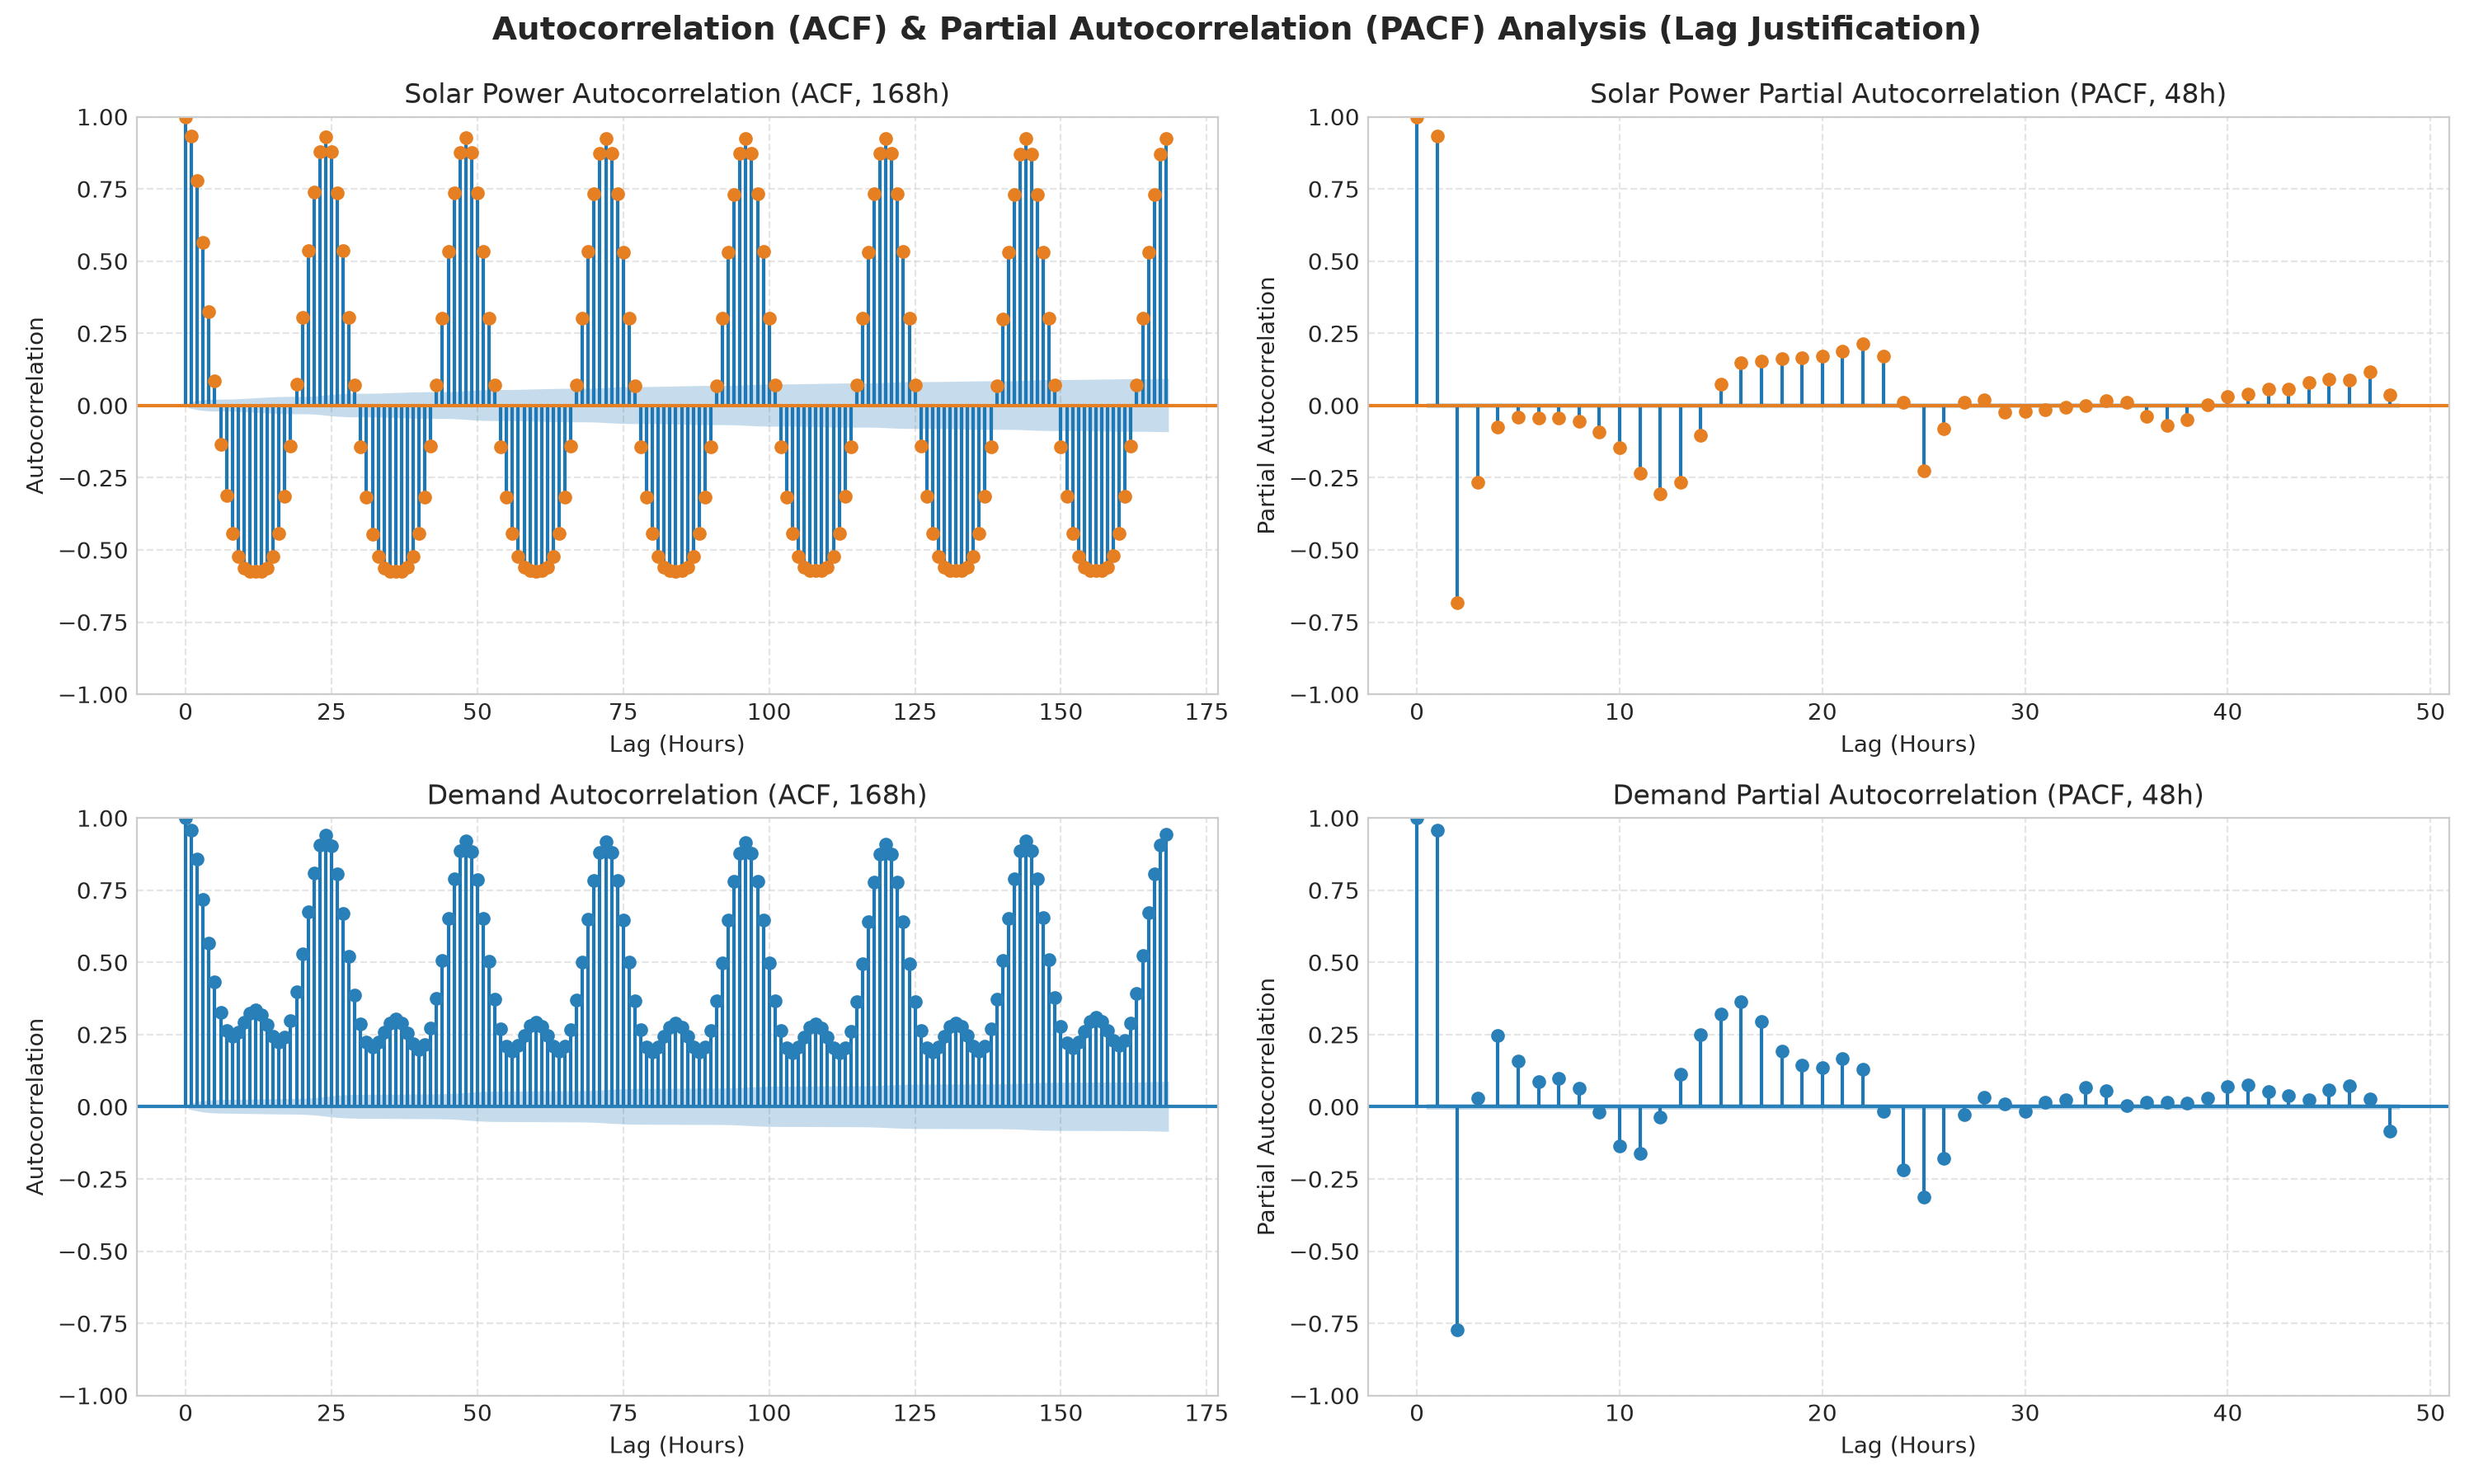

In [11]:
fig09_path = plot_acf_pacf_analysis(df)
display(Image(filename=str(fig09_path)))

**Autocorrelation (ACF & PACF) Insights — Statistical Justification for M4 Lags**:
- **Spike at Lag 1 to 3**: Strong short-term inertia in both demand and solar, validating autoregressive lags $t-1, t-2, t-3$.
- **Spike at Lag 24 & 48**: Clear, repeating cyclical peaks at multiples of 24 hours ($t-24, t-48$), proving the diurnal daily periodicity.
- **Spike at Lag 168**: Prominent autocorrelation peak at 168 hours ($7 \text{ days} \times 24 \text{ hours}$), mathematically proving that the weekly seasonal lag ($t-168$) is essential for capturing workweek cycles.

## 5. Cross-Feature Correlation Matrix

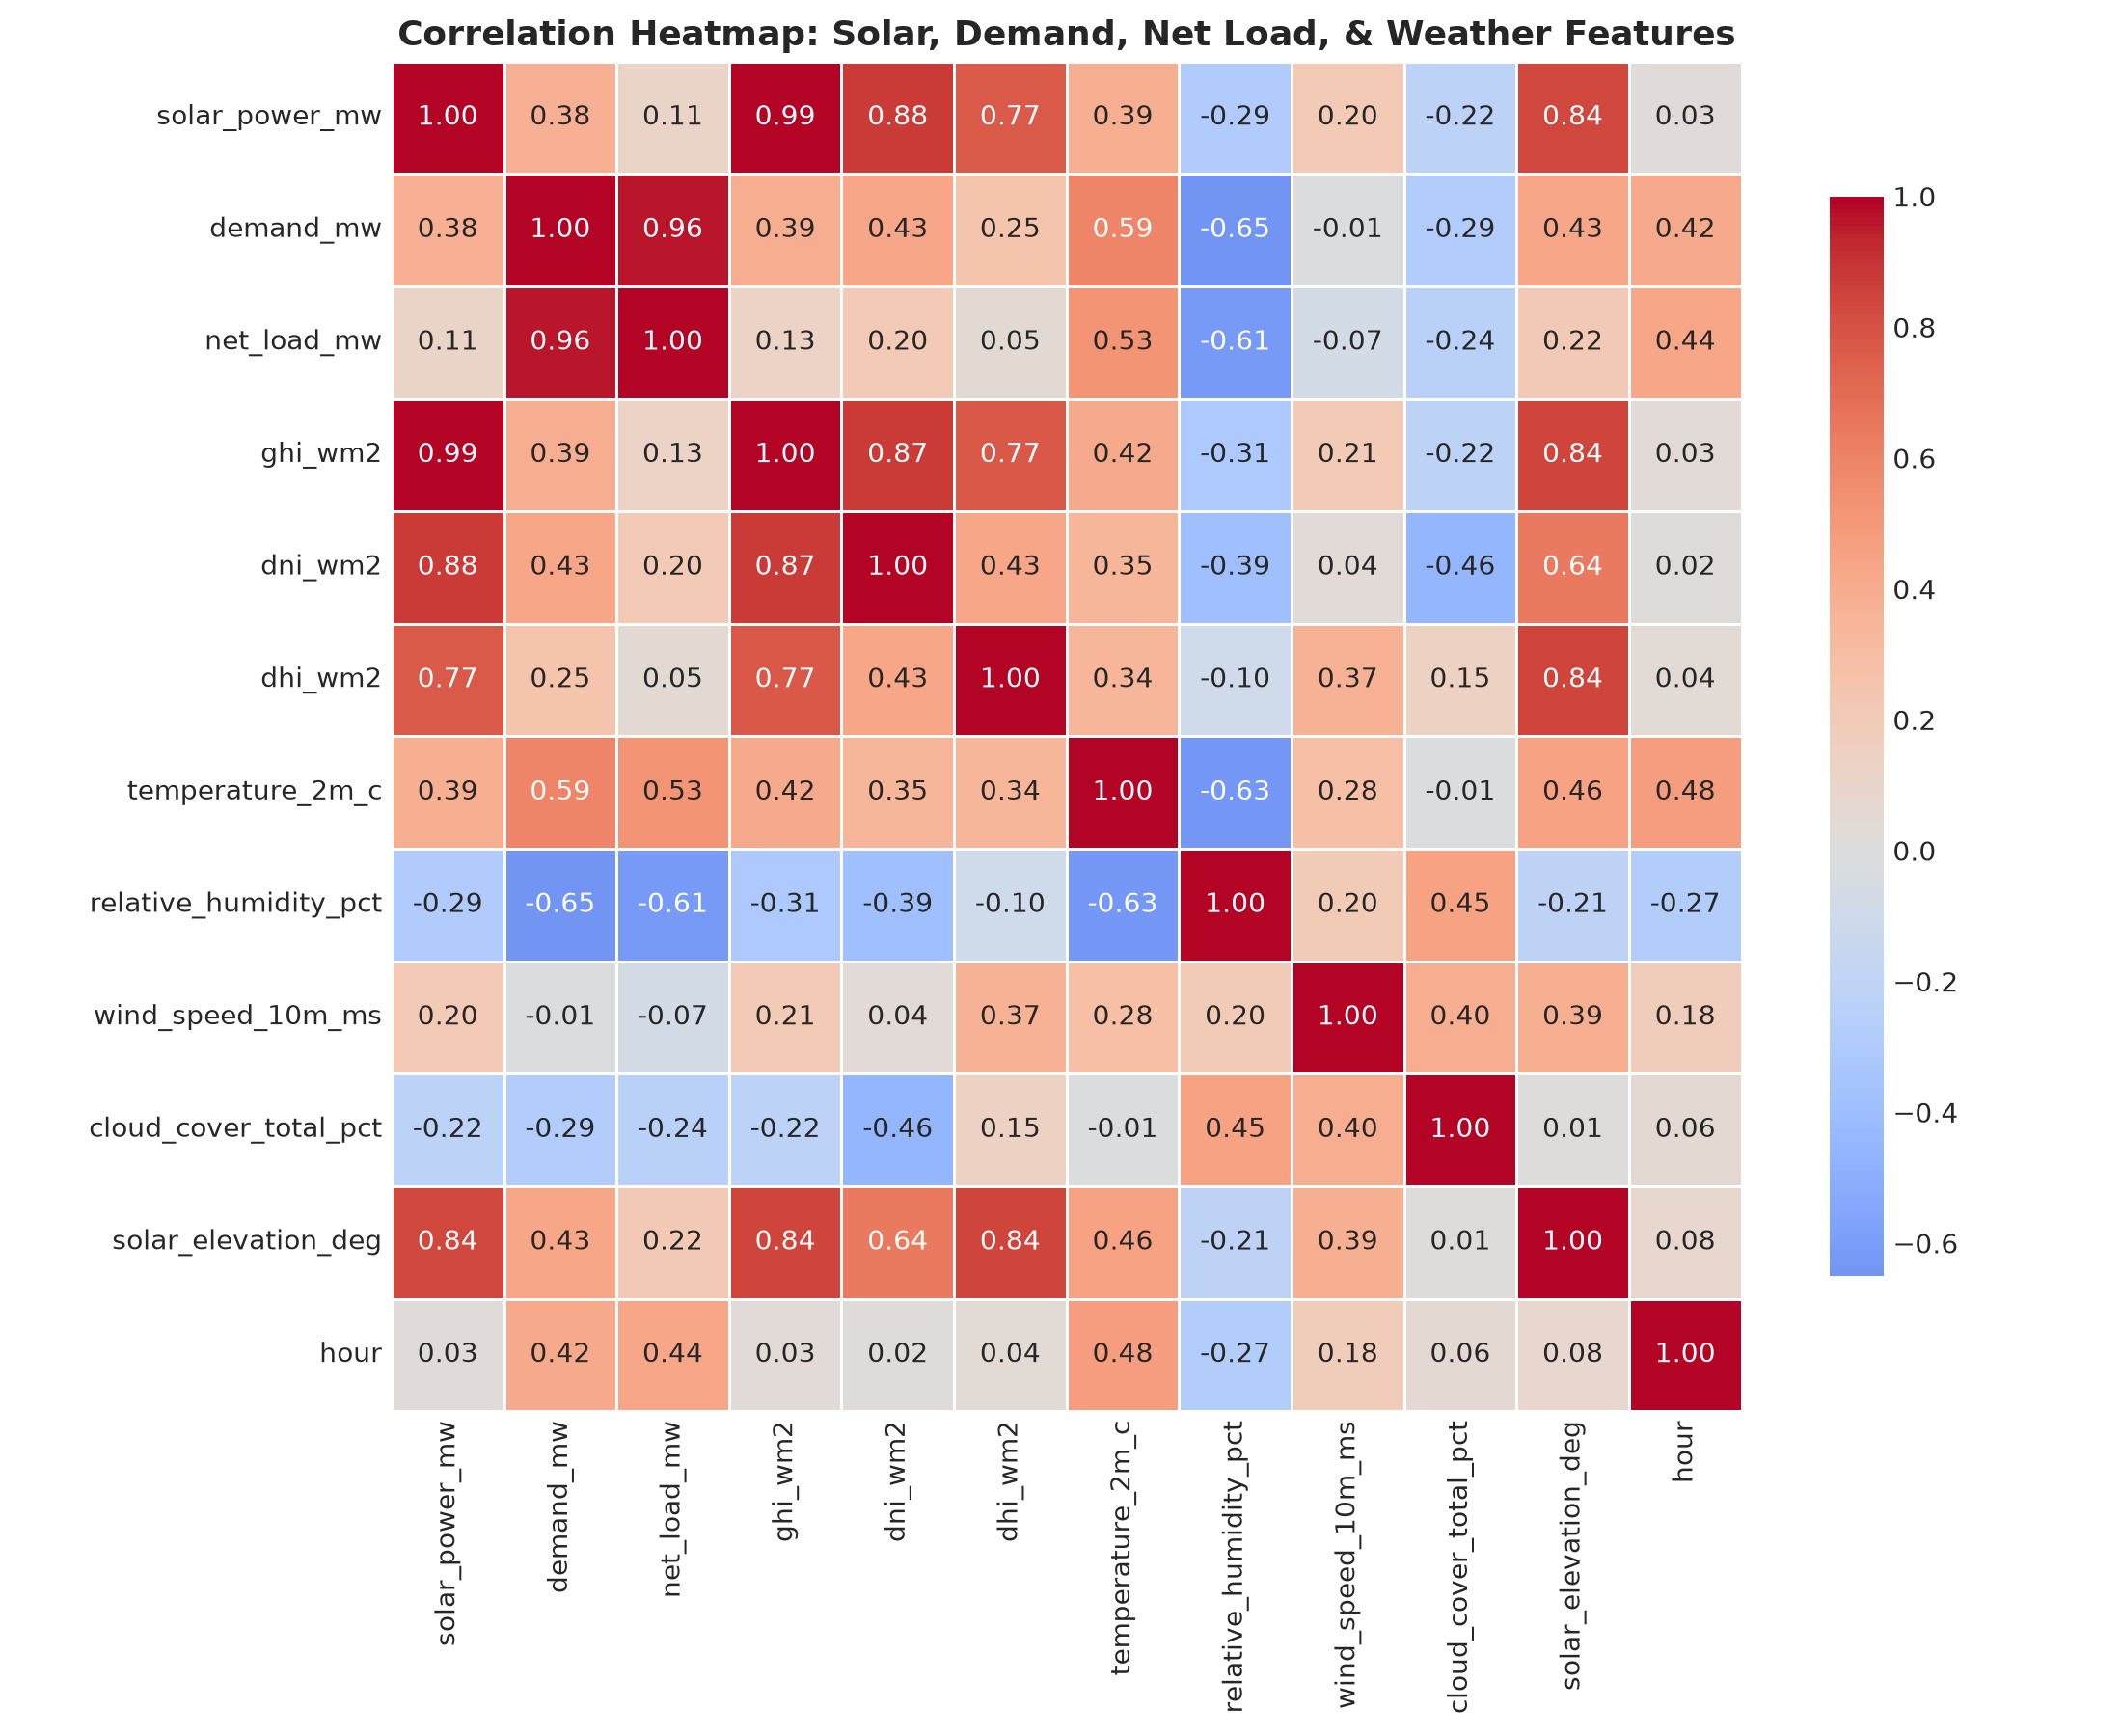

In [12]:
fig07_path = plot_correlation_heatmap(df)
display(Image(filename=str(fig07_path)))

## 6. Milestone 3 Summary & Viva Defense Takeaways
1. **Solar Diurnal Profile**: Strict 12:00-13:00 IST peak (~1,850 MW) with zero night generation.
2. **Seasonal Variability**: CUF fluctuates between 25-28% (summer) and 15-18% (monsoon).
3. **Dual Demand Peaks**: 09:00-11:00 IST morning ramp and 19:00-20:00 IST evening peak.
4. **Thermal Gradient**: +115.1 MW/°C demand sensitivity to ambient temperature.
5. **Physical GHI Coupling**: Direct linear coupling ($r=0.96$) validates solar simulation physics.
6. **Duck Curve Ramp**: ~2,800 MW net-load ramp required over 3 evening hours.
7. **Macro Growth**: +5.5%/yr secular demand escalation.
8. **ACF/PACF Lag Justification**: Prominent spikes at lags 24 and 168 statistically validate the M4 feature set ($t-1, t-2, t-3, t-24, t-48, t-168$).
9. **Stationarity**: Confirmed via ADF tests ($p < 0.001$).
10. **Ramp Tail Risk**: P99 net load ramp is +1,308.5 MW/hour, providing critical dispatch limits for grid stability.

The dataset is fully characterized and verified. We are ready to proceed to **Milestone 4 (Features and Splits)**.